basics numpy pandas

In [1]:
import numpy as np
P = np.zeros((10, 10), dtype=int)
P[:, 0] = 1
for i in range(1, 10):
    P[i, 1:] = P[i-1, 1:] + P[i-1, :-1]
print("Hàng 4:", P[4, :5])
print("Hàng 9:", P[9, :10])
print("P[9, 4] =", P[9, 4])
print("Tổng hàng 9 =", np.sum(P[9, :]))
assert P[9, 4] == 126
assert np.sum(P[9, :]) == 512

Hàng 4: [1 4 6 4 1]
Hàng 9: [  1   9  36  84 126 126  84  36   9   1]
P[9, 4] = 126
Tổng hàng 9 = 512
Các kiểm tra đều đúng!


In [2]:
import numpy as np
A = np.array([
    [2, 1, -1, 0],
    [1, 3, 2, 1],
    [0, -1, 4, 2],
    [3, 0, 1, 5]
], dtype=float)

x_star = np.array([1, -1, 2, 3], dtype=float)
b = A @ x_star

print("Ma trận A:")
print(A)
print("\nVéc tơ b:")
print(b)

x = np.linalg.solve(A, b)
print(x)

print("\nKết quả kiểm tra:", np.allclose(x, x_star))

A_moi = A.copy()
A_moi[3] = A_moi[0] + A_moi[1]
print(A_moi)
try:
    x_moi = np.linalg.solve(A_moi, b)
    print("Nghiệm mới:", x_moi)

except np.linalg.LinAlgError as e:
    print("Lỗi của solve:", e)

Ma trận A:
[[ 2.  1. -1.  0.]
 [ 1.  3.  2.  1.]
 [ 0. -1.  4.  2.]
 [ 3.  0.  1.  5.]]

Véc tơ b:
[-1.  5. 15. 20.]

Nghiệm tìm được:
[ 1. -1.  2.  3.]

Kết quả kiểm tra: True

Ma trận A sau khi thay hàng 4:
[[ 2.  1. -1.  0.]
 [ 1.  3.  2.  1.]
 [ 0. -1.  4.  2.]
 [ 3.  4.  1.  1.]]
Nghiệm mới: [ 2.32801458e+17 -6.65147022e+16  3.99088213e+17 -8.31433777e+17]


In [3]:
import numpy as np
x = np.array([0, 1, 2, 3], dtype=float)
y = np.array([1, 0, 5, 22], dtype=float)
V = np.vander(x, increasing=True)
print(V)

c = np.linalg.solve(V, y)

print("c0 =", c[0])
print("c1 =", c[1])
print("c2 =", c[2])
print("c3 =", c[3])
y_tinh = V @ c
print("\nGiá trị tính được:", y_tinh)
print("Kiểm tra:", np.allclose(y_tinh, y))
x_can_tinh = 1.5
p = c[0] + c[1]*x_can_tinh + c[2]*x_can_tinh**2 + c[3]*x_can_tinh**3
print("\np(1.5) =", p)

Ma trận Vandermonde:
[[ 1.  0.  0.  0.]
 [ 1.  1.  1.  1.]
 [ 1.  2.  4.  8.]
 [ 1.  3.  9. 27.]]

Các hệ số đa thức:
c0 = 1.0
c1 = -2.0
c2 = -1.3322676295501878e-15
c3 = 1.0000000000000004

Giá trị tính được: [ 1.0000000e+00 -8.8817842e-16  5.0000000e+00  2.2000000e+01]
Kiểm tra: True

p(1.5) = 1.3749999999999982


In [6]:
import numpy as np
import time

rng = np.random.default_rng(0)
A = rng.random((500, 500))
b = rng.random(500)
start = time.perf_counter()
x1 = np.linalg.solve(A, b)
time_solve = time.perf_counter() - start
start = time.perf_counter()
x2 = np.linalg.inv(A) @ b
time_inv = time.perf_counter() - start

residual1 = np.linalg.norm(A @ x1 - b)
residual2 = np.linalg.norm(A @ x2 - b)

print("\nCách 1: np.linalg.solve()")
print("Phần dư:", residual1)
print("Thời gian:", time_solve, "giây")

print("\nCách 2: np.linalg.inv(A) @ b")
print("Phần dư:", residual2)
print("Thời gian:", time_inv, "giây")

print("\nHai nghiệm giống nhau:", np.allclose(x1, x2))

assert residual1 < 1e-8
assert residual2 < 1e-8
assert np.allclose(x1, x2, rtol=1e-5, atol=1e-8)


Cách 1: np.linalg.solve()
Phần dư: 1.0588221665204938e-12
Thời gian: 0.001844399999754387 giây

Cách 2: np.linalg.inv(A) @ b
Phần dư: 2.8011148668993273e-12
Thời gian: 0.003863699999783421 giây

Hai nghiệm giống nhau: True


In [8]:
import pandas as pd
danh_sach = []
while True:
    ho_ten = input("Nhập họ tên (Enter để kết thúc): ")

    if ho_ten == "":
        break
    ma_sv = input("Nhập mã sinh viên: ")
    ngay_sinh = input("Nhập ngày sinh (dd/mm/yyyy): ")

    danh_sach.append({
        "HoTen": ho_ten,
        "MaSV": ma_sv,
        "NgaySinh": ngay_sinh
    })
df = pd.DataFrame(danh_sach)
df["NgaySinh"] = pd.to_datetime(
    df["NgaySinh"],
    format="%d/%m/%Y"
)
moc_thoi_gian = pd.Timestamp("2026-01-01")

df["Tuoi"] = (
    (moc_thoi_gian - df["NgaySinh"]).dt.days / 365.25
).astype(int)
df.to_excel("students.xlsx", index=False)
print(df)
df_kiem_tra = pd.read_excel("students.xlsx")

print("\nDữ liệu đọc lại từ students.xlsx:")
print(df_kiem_tra)

Nhập họ tên (Enter để kết thúc):  nguyen
Nhập mã sinh viên:  112322323
Nhập ngày sinh (dd/mm/yyyy):  11/11/2007
Nhập họ tên (Enter để kết thúc):  


    HoTen       MaSV   NgaySinh  Tuoi
0  nguyen  112322323 2007-11-11    18

Dữ liệu đọc lại từ students.xlsx:
    HoTen       MaSV   NgaySinh  Tuoi
0  nguyen  112322323 2007-11-11    18


   Height_in  Weight_lb  Weight(Pounds)  Height_cm  Weight_kg           BMI
0          1      65.78          112.99       2.54  29.837306  46247.916949
1          2      71.52          136.49       5.08  32.440926  12570.884084
2          3      69.40          153.03       7.62  31.479310   5421.447647
3          4      68.22          142.34      10.16  30.944071   2997.712920
4          5      67.79          144.30      12.70  30.749027   1906.443472

Số ô thiếu:
Height_in         0
Weight_lb         3
Weight(Pounds)    4
Height_cm         0
Weight_kg         0
BMI               0
dtype: int64

=== BƯỚC 2: SỐ NGƯỜI CÓ BMI < 18.5 ===
149
Nhom_chieu_cao
Thap           66
Trung binh      2
Cao           132
Name: count, dtype: int64
Nhom_chieu_cao
Thap          0.227273
Trung binh    1.000000
Cao           1.000000
Name: BMI_thap, dtype: float64


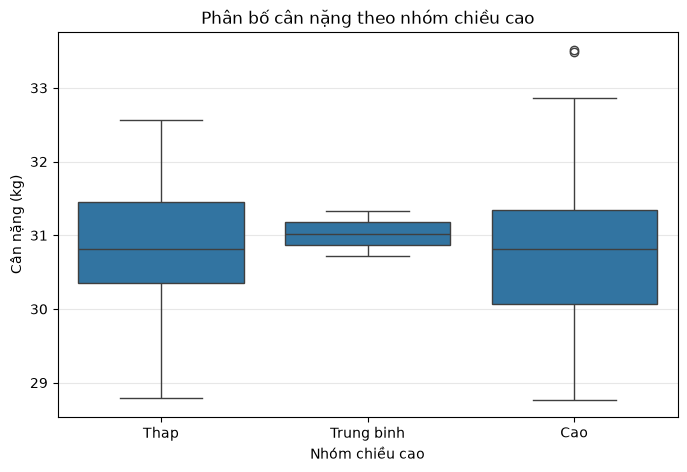


Đã lưu biểu đồ vào file box.png


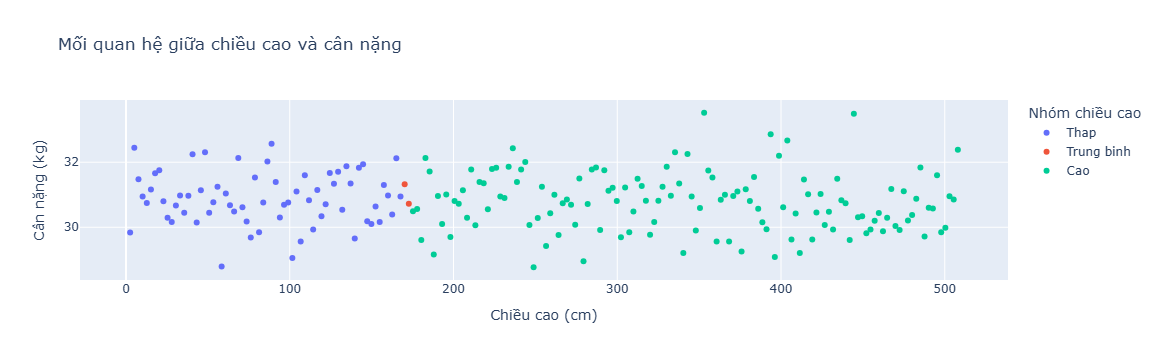

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv(r"E:\lập trình python\200heightsweights.csv")
df = (
    df.rename(columns={
        df.columns[0]: "Height_in",
        df.columns[1]: "Weight_lb"
    })
    .assign(
        Height_in=lambda x: pd.to_numeric(x["Height_in"], errors="coerce"),
        Weight_lb=lambda x: pd.to_numeric(x["Weight_lb"], errors="coerce")
    )
    .assign(
        Height_cm=lambda x: x["Height_in"] * 2.54,
        Weight_kg=lambda x: x["Weight_lb"] * 0.45359237
    )
    .assign(
        Height_cm=lambda x: x["Height_cm"].fillna(x["Height_cm"].mean()),
        Weight_kg=lambda x: x["Weight_kg"].fillna(x["Weight_kg"].mean())
    )
    .assign(
        BMI=lambda x: x["Weight_kg"] / (x["Height_cm"] / 100) ** 2
    )
)

print(df.head())
print("\nSố ô thiếu:")
print(df.isnull().sum())
so_nguoi_thieu_can = (df["BMI"] < 18.5).sum()

print("\n=== BƯỚC 2: SỐ NGƯỜI CÓ BMI < 18.5 ===")
print(so_nguoi_thieu_can)

df["Nhom_chieu_cao"] = pd.cut(
    df["Height_cm"],
    bins=[-np.inf, 170, 175, np.inf],
    labels=["Thap", "Trung binh", "Cao"],
    right=False
)
print(df["Nhom_chieu_cao"].value_counts().sort_index())

ti_le = (
    df.assign(BMI_thap=df["BMI"] < 18.5)
      .groupby("Nhom_chieu_cao", observed=False)["BMI_thap"]
      .mean()
)
print(ti_le)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Nhom_chieu_cao",
    y="Weight_kg"
)

plt.title("Phân bố cân nặng theo nhóm chiều cao")
plt.xlabel("Nhóm chiều cao")
plt.ylabel("Cân nặng (kg)")
plt.grid(axis="y", alpha=0.3)

plt.savefig("box.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nĐã lưu biểu đồ vào file box.png")

try:
    import plotly.express as px

    fig = px.scatter(
        df,
        x="Height_cm",
        y="Weight_kg",
        color="Nhom_chieu_cao",
        title="Mối quan hệ giữa chiều cao và cân nặng",
        labels={
            "Height_cm": "Chiều cao (cm)",
            "Weight_kg": "Cân nặng (kg)",
            "Nhom_chieu_cao": "Nhóm chiều cao"
        },
        hover_data=["BMI"]
    )

    fig.show()

except ImportError:
    print("\nChưa cài Plotly. Chạy lệnh: !pip install plotly")


In [14]:
import pandas as pd
df = pd.read_csv(r"E:\lập trình python\core_HRdata.csv")
df["Department"] = df["Department"].str.strip()

print(df["Department"].unique())
print("Số phòng ban:", df["Department"].nunique())
bang_luong = (
    df.groupby(["Department", "Sex"])["Pay Rate"]
      .mean()
      .unstack()
)
print("\nBẢNG LƯƠNG TRUNG BÌNH ")
print(bang_luong)


df["Date of Hire"] = pd.to_datetime(df["Date of Hire"])
moc = pd.Timestamp("2017-01-01")

df["Tham_nien"] = (
    (moc - df["Date of Hire"]).dt.days // 365
)
top_5 = df.sort_values(
    by=["Tham_nien", "Employee Name"],
    ascending=[False, True]
).head(5)

print("\nNHÂN VIÊN CÓ THÂM NIÊN CAO NHẤT")
print(top_5[["Employee Name", "Date of Hire", "Tham_nien"]])

thong_ke = df["Performance Score"].value_counts().sort_index()

print("\nSỐ NHÂN VIÊN THEO PERFORMANCE SCORE")
print(thong_ke)


<ArrowStringArray>
[       'Admin Offices',     'Executive Office',                'IT/IS',
           'Production',                'Sales', 'Software Engineering']
Length: 6, dtype: str
Số phòng ban: 6

BẢNG LƯƠNG TRUNG BÌNH 
Sex                      Female       Male
Department                                
Admin Offices         26.160000  40.500000
Executive Office      80.000000        NaN
IT/IS                 42.536316  46.740455
Production            22.613701  23.827284
Sales                 55.683333  55.375000
Software Engineering  52.330000  43.167500

NHÂN VIÊN CÓ THÂM NIÊN CAO NHẤT
        Employee Name Date of Hire  Tham_nien
282  Riordan, Michael   2006-01-09         10
165       Pitt, Brad    2007-11-05          9
254  Thibaud, Kenneth   2007-06-25          9
68       Alagbe,Trina   2008-01-07          8
0          Brown, Mia   2008-10-27          8

SỐ NHÂN VIÊN THEO PERFORMANCE SCORE
Performance Score
90-day meets                 31
Exceeds                      28
E